# Exploratory Data Analysis: April–August 2026

This notebook explores the five-month portion of `data/soil_extended.csv` from **2026-04-01 through 2026-08-31** (inclusive). It checks data coverage and quality, summarizes sensor and weather variables, and visualizes temporal patterns and relationships.

Run from the repository root or open the notebook in VS Code/Jupyter. The data path is resolved relative to the current directory or this notebook's parent directories.

In [19]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.titleweight"] = "bold"

DATA_PATH = next(
    (candidate for candidate in [Path.cwd() / "data" / "soil_extended.csv",
                                 Path.cwd().parent / "data" / "soil_extended.csv"] if candidate.exists()),
    None,
)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find data/soil_extended.csv from the current directory or its parent.")

START = pd.Timestamp("2025-12-14 00:00:00")
END_EXCLUSIVE = pd.Timestamp("2026-09-01 00:00:00")
df_all = pd.read_csv(DATA_PATH, parse_dates=["ts"])
df = (df_all.loc[df_all["ts"].ge(START) & df_all["ts"].lt(END_EXCLUSIVE)]
      .sort_values("ts")
      .set_index("ts"))

SENSOR_COLS = ["temperature", "humidity", "light", "soiltemp", "moisture", "pH", "EC", "N", "P", "K"]
WEATHER_COLS = ["w_air_T", "w_air_RH", "w_rad", "w_rain_5min"]
SENSOR_COLS = [column for column in SENSOR_COLS if column in df.columns]
WEATHER_COLS = [column for column in WEATHER_COLS if column in df.columns]
NUMERIC_COLS = df.select_dtypes(include="number").columns.tolist()

print(f"Source: {DATA_PATH.resolve()}")
print(f"Selected rows: {len(df):,} | {df.index.min()} to {df.index.max()}")
print(f"Sensor variables: {SENSOR_COLS}")
print(f"Weather variables: {WEATHER_COLS}")
df.head()

Source: D:\smart_farm\Data-Processing\data\soil_extended.csv
Selected rows: 75,168 | 2025-12-14 00:00:00 to 2026-08-31 23:55:00
Sensor variables: ['temperature', 'humidity', 'light', 'soiltemp', 'moisture', 'pH', 'EC', 'N', 'P', 'K']
Weather variables: ['w_air_T', 'w_air_RH', 'w_rad', 'w_rain_5min']


,temperature,humidity,light,soiltemp,moisture,pH,EC,N,P,K,source,w_air_T,w_air_RH,w_rad,w_rain_5min,stage
ts,,,,,,,,,,,,,,,,
2025-12-14 00:00:00,12.67,24.51,0.00,27.48,42.05,5.60,1.21,277.15,800.21,850.68,real,23.70,99.000,0.0,0.008,truoc_11_01
2025-12-14 00:05:00,12.98,25.38,0.00,27.12,41.54,5.57,1.20,277.19,802.93,852.14,real,23.75,98.833,0.0,0.008,truoc_11_01
2025-12-14 00:10:00,12.48,24.90,0.50,27.17,41.06,5.57,1.21,275.22,801.44,853.75,real,23.80,98.667,0.0,0.008,truoc_11_01
2025-12-14 00:15:00,12.96,24.69,1.09,27.02,40.90,5.59,1.23,273.26,799.80,853.39,real,23.85,98.500,0.0,0.008,truoc_11_01
2025-12-14 00:20:00,12.70,25.21,2.17,27.46,41.77,5.59,1.20,273.42,802.22,852.05,real,23.90,98.333,0.0,0.008,truoc_11_01


## Coverage and data quality

The source is sampled every five minutes, so a fully covered five-month interval contains 44,064 timestamps. The checks below report observed coverage rather than assuming it is complete.

In [20]:
expected_index = pd.date_range(START, END_EXCLUSIVE - pd.Timedelta(minutes=5), freq="5min")
missing_timestamps = expected_index.difference(df.index)
duplicate_timestamps = int(df.index.duplicated().sum())
step_counts = df.index.to_series().diff().value_counts().head(8)

coverage = pd.Series({
    "expected timestamps": len(expected_index),
    "observed rows": len(df),
    "missing timestamps": len(missing_timestamps),
    "duplicate timestamps": duplicate_timestamps,
    "observed coverage (%)": round(100 * len(df.index.unique()) / len(expected_index), 2),
})
display(coverage.to_frame("value"))
display(pd.DataFrame({"row count": df.resample("MS").size()}))
display(step_counts.rename_axis("interval").to_frame("count"))

,value
expected timestamps,75168.0
observed rows,75168.0
missing timestamps,0.0
duplicate timestamps,0.0
observed coverage (%),100.0


,row count
ts,
2025-12-01,5184
2026-01-01,8928
2026-02-01,8064
2026-03-01,8928
2026-04-01,8640
2026-05-01,8928
2026-06-01,8640
2026-07-01,8928
2026-08-01,8928


,count
interval,
0 days 00:05:00,75167


In [21]:
quality = pd.DataFrame({
    "missing_count": df[NUMERIC_COLS].isna().sum(),
    "missing_percent": (100 * df[NUMERIC_COLS].isna().mean()).round(2),
    "unique_values": df[NUMERIC_COLS].nunique(),
    "minimum": df[NUMERIC_COLS].min(),
    "maximum": df[NUMERIC_COLS].max(),
}).sort_values("missing_percent", ascending=False)
display(quality)

if "source" in df.columns:
    display(df["source"].value_counts(dropna=False).rename("rows").to_frame())
if "stage" in df.columns:
    display(pd.crosstab(df.index.to_period("M").astype(str), df["stage"], margins=True))

,missing_count,missing_percent,unique_values,minimum,maximum
light,1830,2.43,1596,0.00,27.900
EC,863,1.15,185,0.00,2.080
P,862,1.15,44100,0.00,1551.110
N,842,1.12,24108,0.00,456.050
K,836,1.11,46437,0.00,1409.830
temperature,721,0.96,3304,-0.50,50.530
humidity,701,0.93,8213,0.00,100.000
soiltemp,676,0.90,1062,15.91,38.310
pH,661,0.88,307,3.82,8.130
moisture,661,0.88,4869,0.00,86.180


,rows
source,
synthetic,67104
real,8064


stage,cay_con_vu2,dat_trong_chuan_bi,ra_hoa_vu1,ra_hoa_vu2,ra_qua_vu2,sinh_duong_vu2,thu_hoach_vu1,truoc_11_01,All
row_0,,,,,,,,,
2025-12,0,0,0,0,0,0,0,5184,5184
2026-01,0,0,6048,0,0,0,0,2880,8928
2026-02,0,0,1152,0,0,0,6912,0,8064
2026-03,0,0,0,0,0,0,8928,0,8928
2026-04,0,1728,0,0,0,0,6912,0,8640
2026-05,4320,4032,0,0,0,576,0,0,8928
2026-06,0,0,0,864,0,7776,0,0,8640
2026-07,0,0,0,6048,2880,0,0,0,8928
2026-08,0,0,0,0,8928,0,0,0,8928


## Descriptive statistics

The summary includes all numeric sensor and weather fields available in the CSV. Different variables use different units, so compare values within a variable rather than across columns.

In [22]:
display(df[NUMERIC_COLS].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(3))

monthly_summary = df[NUMERIC_COLS].resample("MS").agg(["mean", "median", "std"])
monthly_summary.columns = [f"{variable}_{stat}" for variable, stat in monthly_summary.columns]
display(monthly_summary.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,max
temperature,74447.0,28.530,5.930,-0.50,19.300,26.440,28.510,32.010,36.110,50.530
humidity,74467.0,68.801,21.549,0.00,30.123,55.225,73.330,86.210,95.600,100.000
light,73338.0,3.449,4.554,0.00,0.000,0.000,0.390,6.700,12.690,27.900
soiltemp,74492.0,27.719,1.863,15.91,25.200,26.400,27.400,28.730,31.440,38.310
moisture,74507.0,47.161,8.840,0.00,27.790,44.640,48.620,52.970,56.780,86.180
pH,74507.0,5.510,0.317,3.82,5.150,5.310,5.470,5.600,6.140,8.130
EC,74305.0,0.576,0.278,0.00,0.200,0.380,0.530,0.750,1.050,2.080
N,74326.0,104.921,74.021,0.00,6.720,52.280,91.965,146.490,242.575,456.050
P,74306.0,358.269,197.816,0.00,89.035,218.880,327.125,478.620,694.668,1551.110
K,74332.0,400.593,220.418,0.00,96.656,239.230,370.660,525.693,805.120,1409.830


,temperature_mean,temperature_median,temperature_std,humidity_mean,humidity_median,humidity_std,light_mean,light_median,light_std,soiltemp_mean,...,w_air_T_std,w_air_RH_mean,w_air_RH_median,w_air_RH_std,w_rad_mean,w_rad_median,w_rad_std,w_rain_5min_mean,w_rain_5min_median,w_rain_5min_std
ts,,,,,,,,,,,,,,,,,,,,,
2025-12-01,17.890,15.95,12.165,32.423,32.970,19.507,1.983,0.01,2.882,26.738,...,3.195,75.556,81.000,17.747,219.009,10.500,290.142,0.008,0.0,0.064
2026-01-01,28.215,28.29,3.749,63.723,64.630,17.166,2.887,0.14,4.075,26.084,...,3.606,65.089,68.500,18.394,219.407,14.500,292.488,0.003,0.0,0.044
2026-02-01,28.866,27.58,3.933,66.341,68.900,19.856,3.575,0.31,4.721,26.885,...,3.497,67.401,69.667,18.561,234.702,18.667,311.810,0.009,0.0,0.046
2026-03-01,28.986,27.66,4.536,68.010,72.670,20.625,4.006,0.43,5.099,27.075,...,3.411,69.812,73.333,18.699,266.698,30.000,337.450,0.003,0.0,0.020
2026-04-01,31.006,29.99,4.789,62.611,66.660,19.273,4.013,0.57,5.034,29.482,...,3.438,64.206,67.333,17.211,270.482,43.875,335.425,0.001,0.0,0.005
2026-05-01,30.962,30.04,4.201,70.383,74.440,17.867,3.646,0.67,4.665,30.581,...,3.112,71.868,75.000,16.109,239.148,40.792,308.109,0.016,0.0,0.060
2026-06-01,29.329,28.49,3.902,80.639,86.150,16.037,3.563,0.58,4.509,28.020,...,2.598,82.099,86.667,13.365,239.250,41.625,300.549,0.025,0.0,0.078
2026-07-01,28.381,27.66,3.957,80.636,85.245,16.289,3.324,0.54,4.317,27.037,...,2.438,82.518,86.000,13.012,220.062,34.916,285.613,0.027,0.0,0.076
2026-08-01,28.877,28.12,3.344,79.317,82.170,13.629,3.353,0.41,4.404,27.142,...,2.212,80.659,82.417,11.229,226.112,33.667,291.928,0.025,0.0,0.086


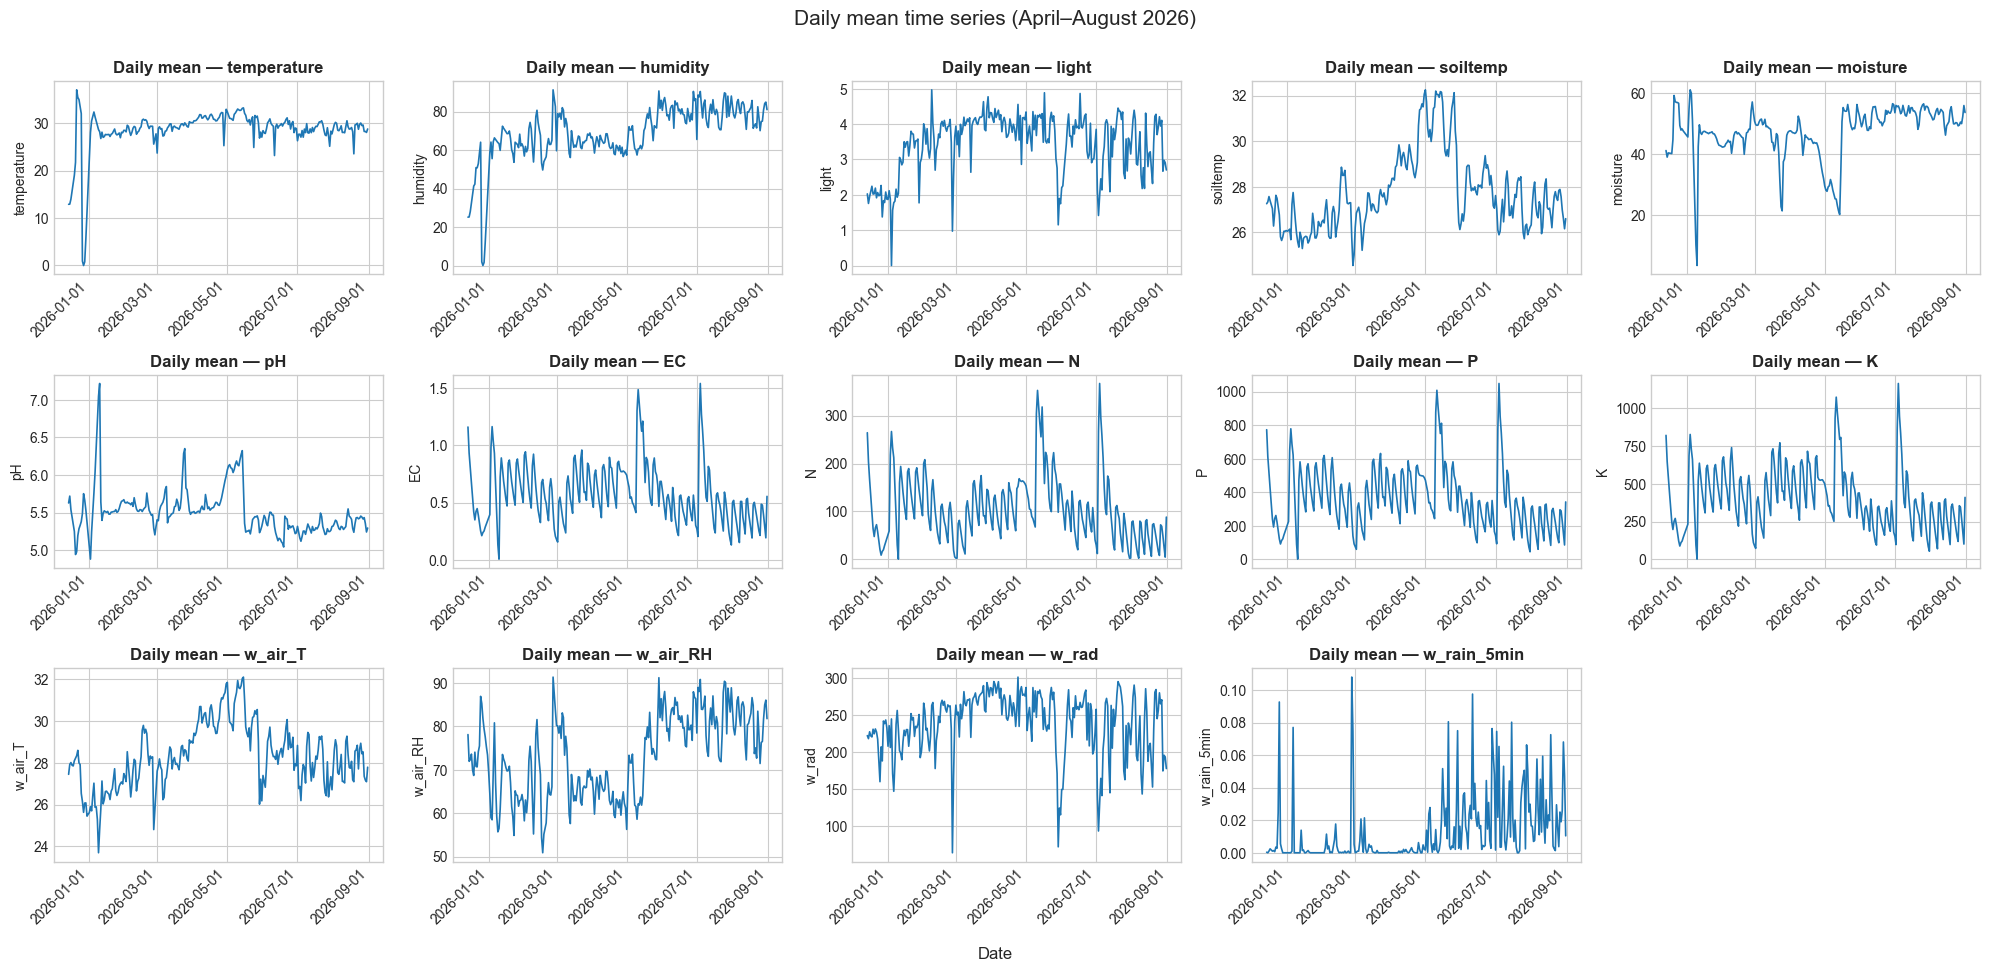

In [30]:
daily = df[NUMERIC_COLS].resample("D").mean()
plot_cols = SENSOR_COLS + WEATHER_COLS
ncols = 5
nrows = int(np.ceil(len(plot_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.2 * nrows), sharex=True)
axes = np.asarray(axes).reshape(-1)
date_locator = mdates.AutoDateLocator(minticks=5, maxticks=8)
date_formatter = mdates.DateFormatter("%Y-%m-%d")
for ax, column in zip(axes, plot_cols):
    ax.plot(daily.index, daily[column], linewidth=1.2)
    ax.set_title(f"Daily mean — {column}")
    ax.set_ylabel(column)
    ax.xaxis.set_major_locator(date_locator)
    ax.xaxis.set_major_formatter(date_formatter)
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
for ax in axes[len(plot_cols):]:
    ax.remove()
fig.suptitle("Daily mean time series (April–August 2026)", y=1.002, fontsize=15)
fig.supxlabel("Date")
fig.tight_layout()
plt.show()

## Within-day patterns

Hourly averages are calculated across the full selected interval. The sensor and weather panels are kept separate to make the different scales easier to read.

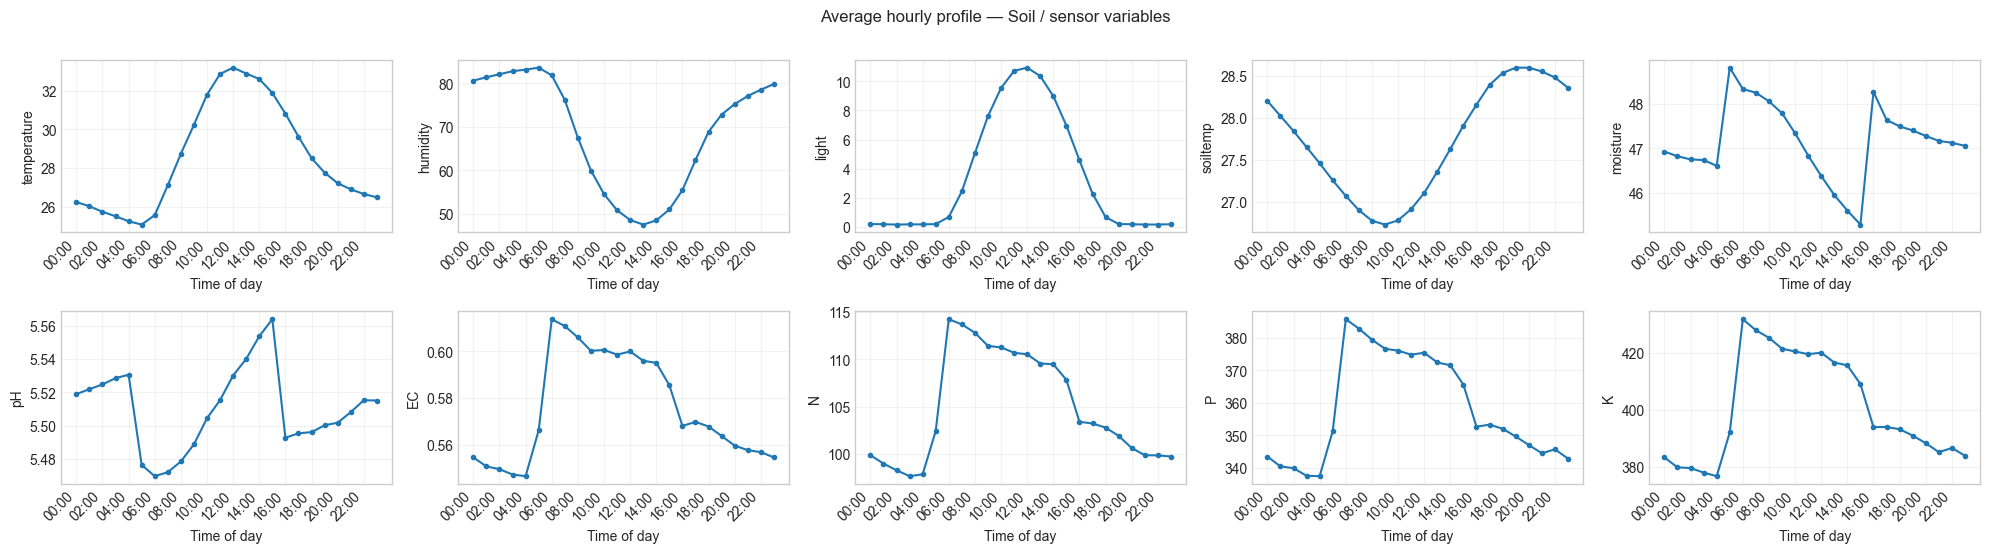

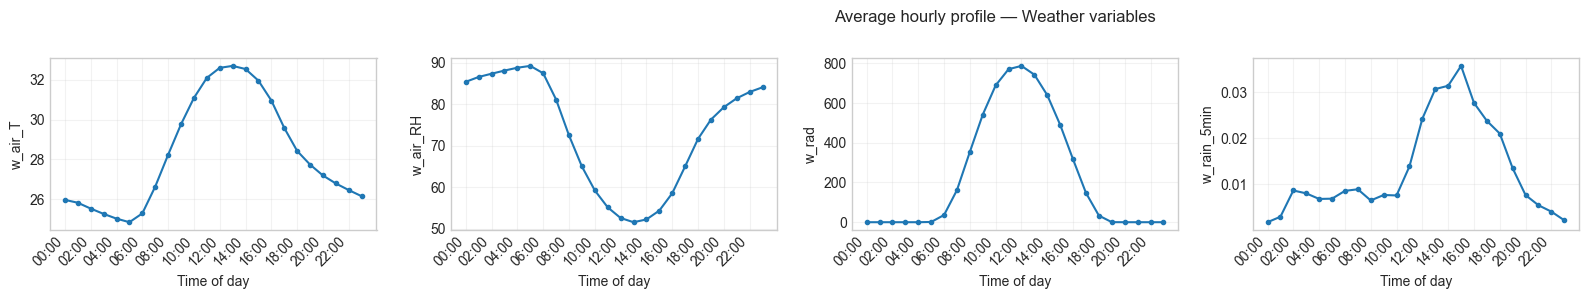

In [32]:
hourly_profile = df.groupby(df.index.hour)[SENSOR_COLS + WEATHER_COLS].mean()
for columns, title in [(SENSOR_COLS, "Soil / sensor variables"), (WEATHER_COLS, "Weather variables")]:
    if not columns:
        continue
    ncols = 5
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, max(2.8 * nrows, 3)), sharex=True)
    axes = np.asarray(axes).reshape(-1)
    for ax, column in zip(axes, columns):
        ax.plot(hourly_profile.index, hourly_profile[column], marker="o", markersize=3)
        ax.set_ylabel(column)
        ax.grid(alpha=0.25)
        ax.set_xticks(range(0, 24, 2), [f"{hour:02d}:00" for hour in range(0, 24, 2)])
        ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
        plt.setp(ax.get_xticklabels(), ha="right")
        ax.set_xlabel("Time of day")
    for ax in axes[len(columns):]:
        ax.remove()
    fig.suptitle(f"Average hourly profile — {title}")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

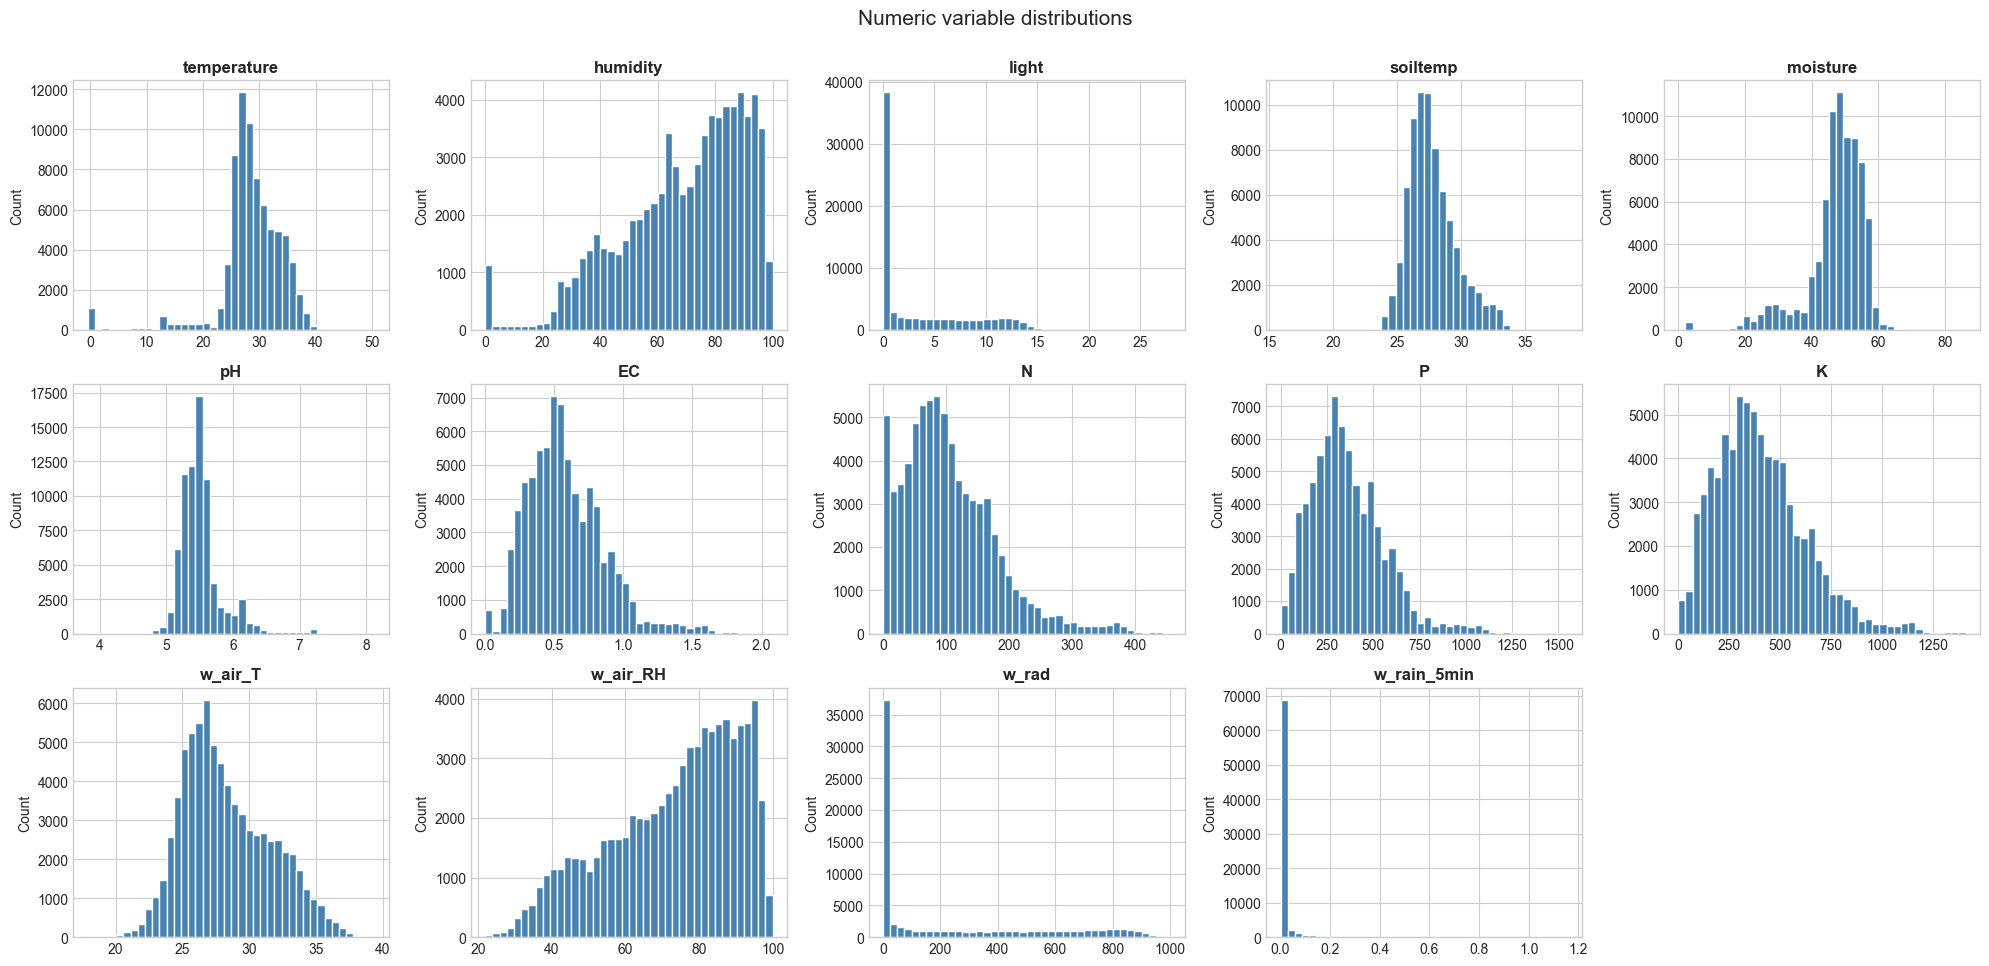

In [34]:
ncols = 5
nrows = int(np.ceil(len(NUMERIC_COLS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.2 * nrows))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, NUMERIC_COLS):
    values = df[column].dropna()
    ax.hist(values, bins=40, color="steelblue", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("Count")
for ax in axes[len(NUMERIC_COLS):]:
    ax.remove()
fig.suptitle("Numeric variable distributions", y=1.002, fontsize=15)
fig.tight_layout()
plt.show()

## Correlations and sensor–weather relationships

Pearson correlations summarize linear co-movement only; they do not establish causation. The heatmaps use pairwise-complete observations.

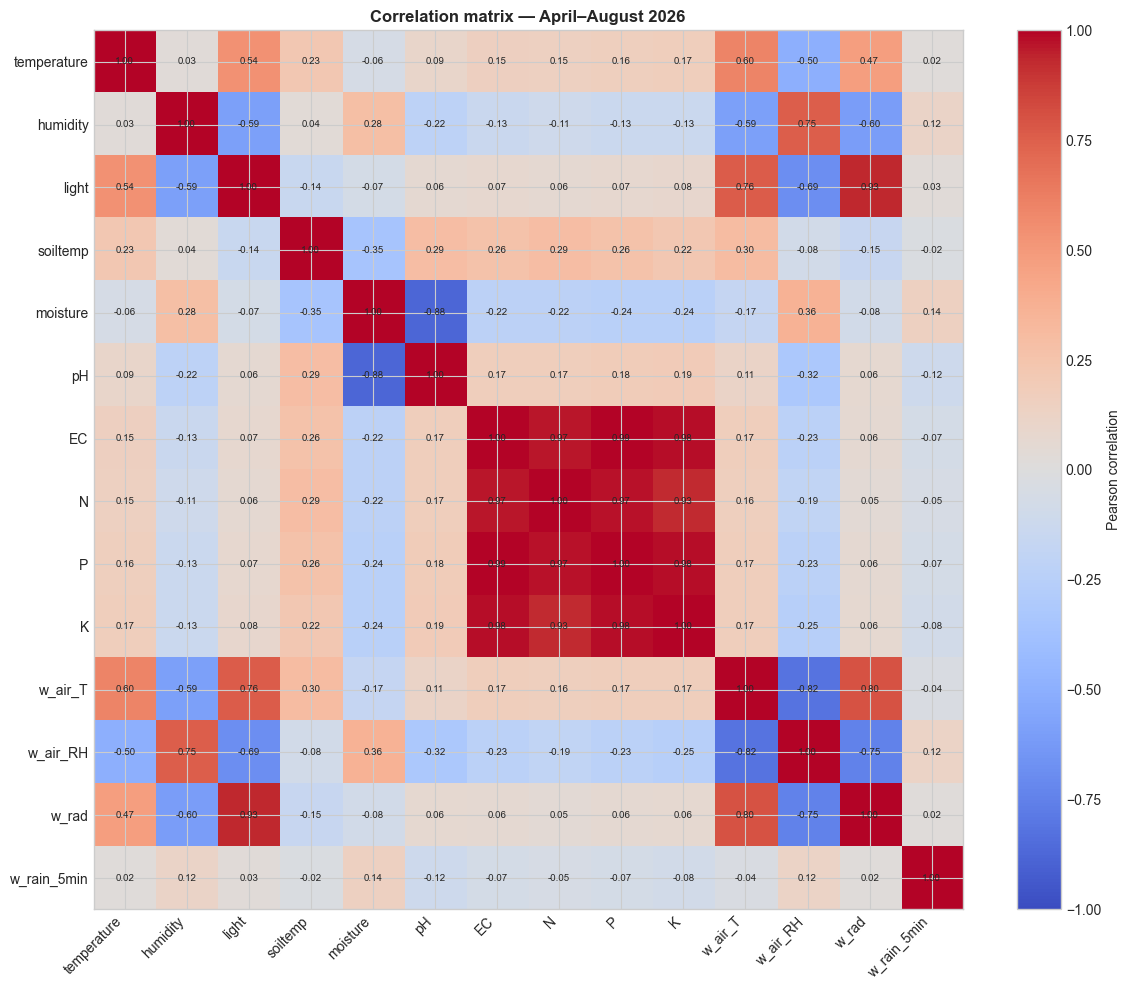

,w_air_T,w_air_RH,w_rad,w_rain_5min
temperature,0.597,-0.497,0.470,0.017
humidity,-0.587,0.751,-0.602,0.116
light,0.759,-0.687,0.931,0.027
soiltemp,0.302,-0.079,-0.154,-0.024
moisture,-0.172,0.361,-0.085,0.145
pH,0.114,-0.315,0.064,-0.117
EC,0.171,-0.227,0.057,-0.069
N,0.161,-0.191,0.046,-0.053
P,0.169,-0.231,0.057,-0.069
K,0.165,-0.251,0.063,-0.079


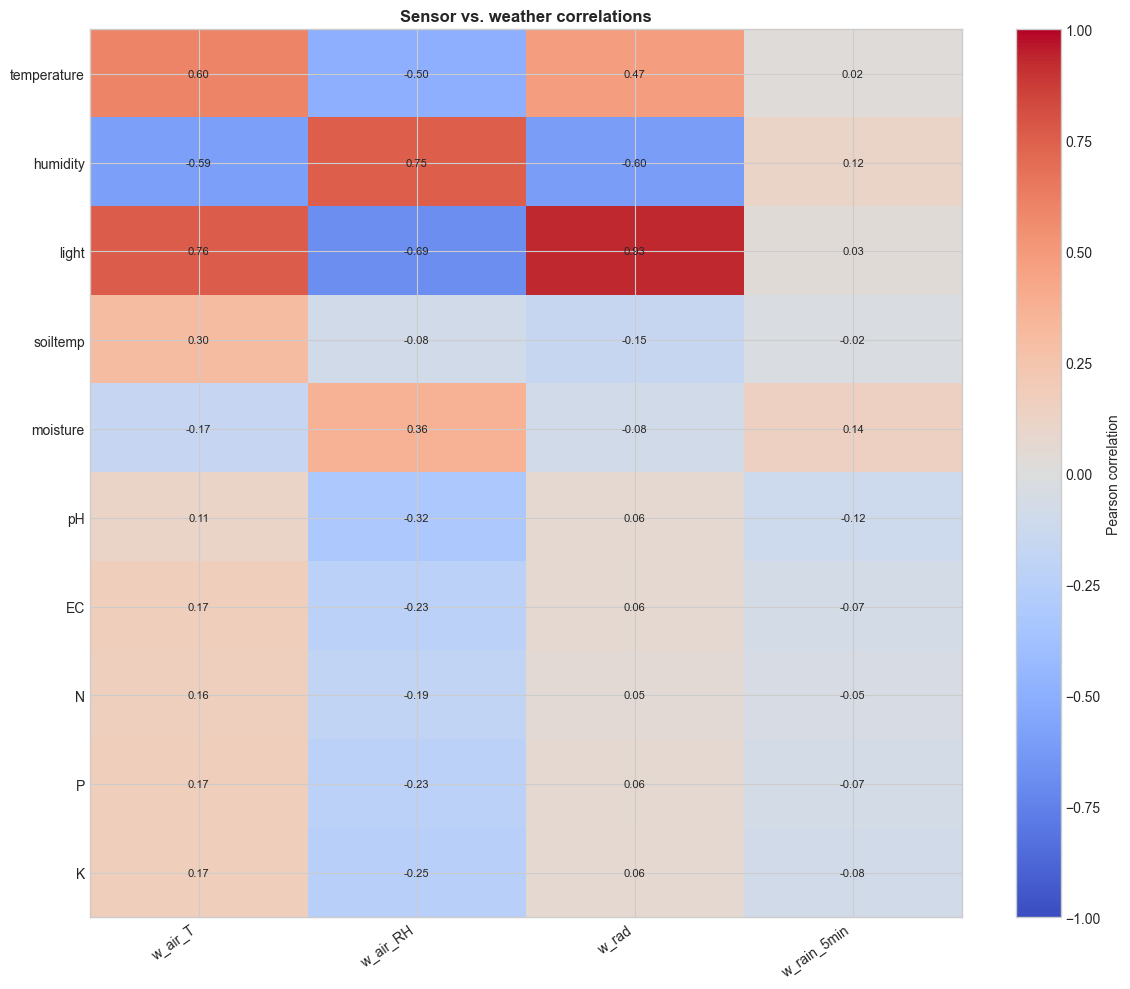

In [35]:
corr = df[NUMERIC_COLS].corr(min_periods=100)
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for row in range(len(corr.index)):
    for col in range(len(corr.columns)):
        value = corr.iat[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix — April–August 2026")
fig.tight_layout()
plt.show()

if SENSOR_COLS and WEATHER_COLS:
    cross_corr = df[SENSOR_COLS + WEATHER_COLS].corr(min_periods=100).loc[SENSOR_COLS, WEATHER_COLS]
    display(cross_corr.round(3))
    fig, ax = plt.subplots(figsize=(12, 10))
    image = ax.imshow(cross_corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(WEATHER_COLS)), WEATHER_COLS, rotation=35, ha="right")
    ax.set_yticks(range(len(SENSOR_COLS)), SENSOR_COLS)
    for row in range(len(SENSOR_COLS)):
        for col in range(len(WEATHER_COLS)):
            value = cross_corr.iat[row, col]
            if pd.notna(value):
                ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    ax.set_title("Sensor vs. weather correlations")
    fig.tight_layout()
    plt.show()

## Monthly changes and follow-up checks

Use these monthly summaries and distribution plots to spot changes worth investigating. The CSV contains raw and weather fields; this notebook does not apply the project's fault flags or imputation pipelines.

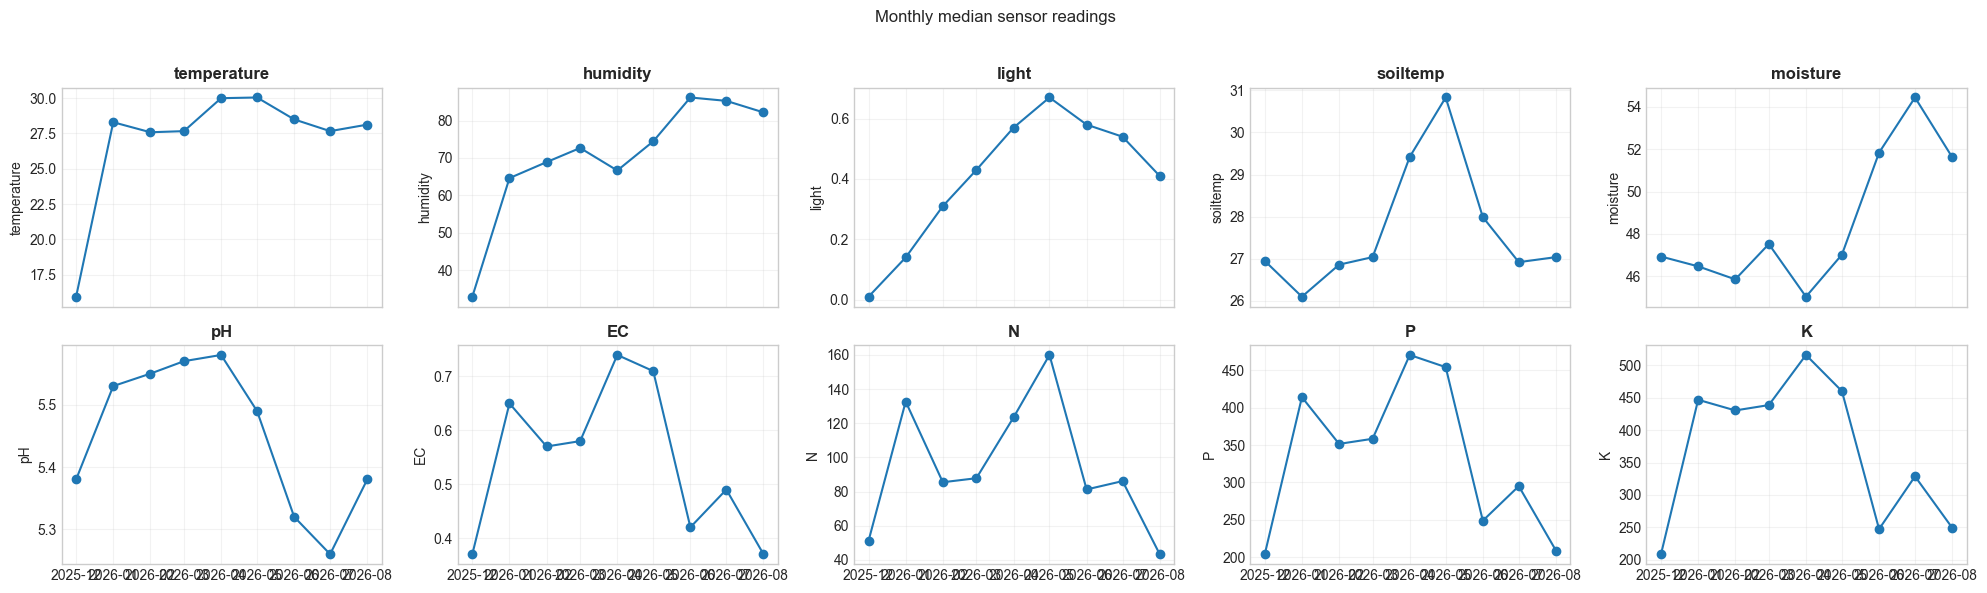

,temperature,humidity,light,soiltemp,moisture,pH,EC,N,P,K,w_air_T,w_air_RH,w_rad,w_rain_5min
ts,,,,,,,,,,,,,,
2025-12-01,15.95,32.970,0.01,26.95,46.930,5.38,0.37,51.155,203.785,208.405,26.483,81.000,10.500,0.0
2026-01-01,28.29,64.630,0.14,26.10,46.465,5.53,0.65,132.660,414.185,446.950,25.400,68.500,14.500,0.0
2026-02-01,27.58,68.900,0.31,26.86,45.850,5.55,0.57,85.450,351.580,430.470,26.775,69.667,18.667,0.0
2026-03-01,27.66,72.670,0.43,27.04,47.520,5.57,0.58,87.810,358.435,438.755,26.900,73.333,30.000,0.0
2026-04-01,29.99,66.660,0.57,29.42,45.030,5.58,0.74,123.380,470.775,516.200,29.233,67.333,43.875,0.0
2026-05-01,30.04,74.440,0.67,30.83,47.020,5.49,0.71,159.975,454.470,460.260,29.262,75.000,40.792,0.0
2026-06-01,28.49,86.150,0.58,27.99,51.840,5.32,0.42,81.225,248.665,247.150,27.733,86.667,41.625,0.0
2026-07-01,27.66,85.245,0.54,26.92,54.450,5.26,0.49,86.115,294.975,328.610,27.100,86.000,34.916,0.0
2026-08-01,28.12,82.170,0.41,27.04,51.630,5.38,0.37,43.330,208.700,249.260,27.400,82.417,33.667,0.0


In [37]:
monthly_median = df[SENSOR_COLS + WEATHER_COLS].resample("MS").median()
n_cols = 5
n_rows = int(np.ceil(len(SENSOR_COLS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, max(3 * n_rows, 3)), sharex=True)
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, SENSOR_COLS):
    ax.plot(monthly_median.index, monthly_median[column], marker="o")
    ax.set_title(column)
    ax.set_ylabel(column)
    ax.grid(alpha=0.25)
for ax in axes[len(SENSOR_COLS):]:
    ax.remove()
fig.suptitle("Monthly median sensor readings")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

display(monthly_median.round(3))